# PRACTICE 1: PyTorch FashionMNIST Classification

**Học phần:** Deep Learning  **UTH** - **Giảng viên:** PHd.Nguyễn Thị Khánh Tiên 
 
 Phân loại ảnh quần áo FashionMNIST bằng PyTorch

## Mục tiêu
1. Làm việc với PyTorch Tensor, Dataset, DataLoader và Transforms.
2. Xây dựng mô hình mạng nơ-ron phân loại ảnh.
3. Hiểu Autograd, hàm mất mát và thuật toán tối ưu.
4. Huấn luyện, đánh giá và so sánh các cấu hình mô hình.
5. Trực quan hóa Loss, Accuracy, kết quả dự đoán và thực hiện lưu/tải mô hình.



## 1. Import thư viện và thiết lập môi trường

In [1]:
import os
import struct
import random
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị đang sử dụng:", device)
print("PyTorch version:", torch.__version__)

Thiết bị đang sử dụng: cpu
PyTorch version: 2.14.1+cpu


## 2. Đọc và khám phá dữ liệu FashionMNIST
FashionMNIST gồm ảnh grayscale kích thước 28×28, 60.000 ảnh huấn luyện và 10.000 ảnh kiểm tra, chia thành 10 lớp.

In [2]:
DATA_DIR = os.path.join("data")

train_images_path = os.path.join(DATA_DIR, "train-images-idx3-ubyte")
train_labels_path = os.path.join(DATA_DIR, "train-labels-idx1-ubyte")
test_images_path = os.path.join(DATA_DIR, "t10k-images-idx3-ubyte")
test_labels_path = os.path.join(DATA_DIR, "t10k-labels-idx1-ubyte")

required_files = [
    train_images_path, train_labels_path,
    test_images_path, test_labels_path
]

missing_files = [path for path in required_files if not os.path.isfile(path)]
if missing_files:
    raise FileNotFoundError(
        "Không tìm thấy các tệp sau: " + ", ".join(missing_files) +
        ". Hãy đặt 4 tệp IDX trực tiếp bên trong thư mục data."
    )

def read_idx_images(file_path):
    with open(file_path, "rb") as file:
        magic, count, rows, cols = struct.unpack(">IIII", file.read(16))
        if magic != 2051:
            raise ValueError(f"File ảnh IDX không hợp lệ: {file_path}")
        images = np.frombuffer(file.read(), dtype=np.uint8)
    return images.reshape(count, rows, cols).copy()

def read_idx_labels(file_path):
    with open(file_path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        if magic != 2049:
            raise ValueError(f"File nhãn IDX không hợp lệ: {file_path}")
        labels = np.frombuffer(file.read(), dtype=np.uint8)
    return labels.astype(np.int64).copy()

train_images = read_idx_images(train_images_path)
train_labels = read_idx_labels(train_labels_path)
test_images = read_idx_images(test_images_path)
test_labels = read_idx_labels(test_labels_path)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Train images:", train_images.shape)
print("Train labels:", train_labels.shape)
print("Test images:", test_images.shape)
print("Test labels:", test_labels.shape)

Train images: (60000, 28, 28)
Train labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


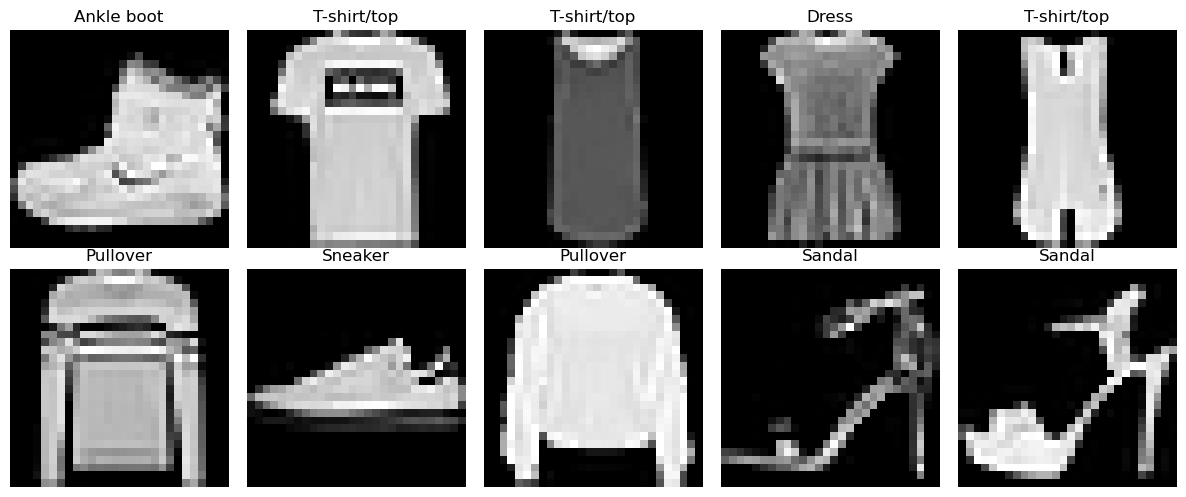

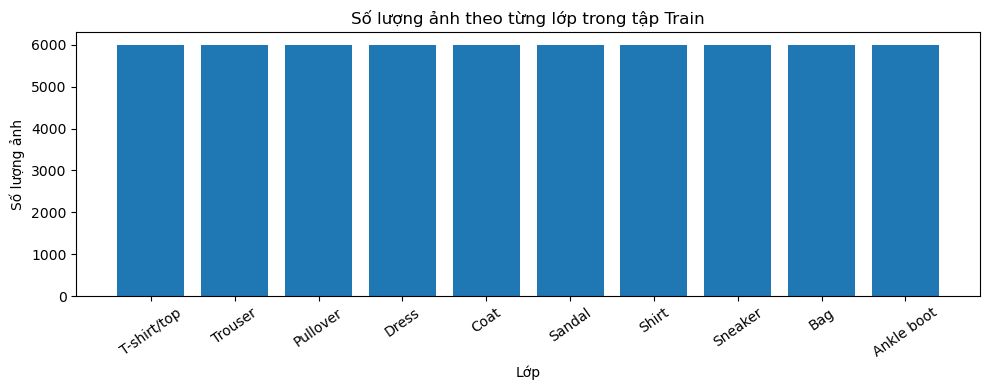

In [3]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_images[i], cmap="gray")
    plt.title(class_names[train_labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

unique, counts = np.unique(train_labels, return_counts=True)
plt.figure(figsize=(10, 4))
plt.bar([class_names[i] for i in unique], counts)
plt.title("Số lượng ảnh theo từng lớp trong tập Train")
plt.xlabel("Lớp")
plt.ylabel("Số lượng ảnh")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## 3. Tiền xử lý và tạo Dataset / DataLoader
- Chuyển ảnh từ `uint8` sang `float32`.
- Chuẩn hóa pixel về khoảng gần [-1, 1].
- Chia tập Train ban đầu thành Train (90%) và Validation (10%).
- Giữ nguyên tập Test chính thức để đánh giá cuối cùng.

In [4]:
class FashionMNISTDataset(Dataset):
    def __init__(self, images, labels):
        images = images.astype(np.float32) / 255.0
        images = (images - 0.5) / 0.5
        self.images = torch.tensor(images, dtype=torch.float32).unsqueeze(1)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.images[index], self.labels[index]

full_train_dataset = FashionMNISTDataset(train_images, train_labels)
test_dataset = FashionMNISTDataset(test_images, test_labels)

train_size = int(0.9 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

batch_size = 128

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train: {len(train_dataset)} ảnh")
print(f"Validation: {len(val_dataset)} ảnh")
print(f"Test: {len(test_dataset)} ảnh")

Train: 54000 ảnh
Validation: 6000 ảnh
Test: 10000 ảnh


## 4. PyTorch Tensor và Transforms

- Ảnh IDX ban đầu là mảng NumPy kiểu `uint8`, có kích thước `(28, 28)` và giá trị pixel từ 0 đến 255.
- Tiền xử lý chuyển ảnh sang `float32`, chia 255 để đưa pixel về [0, 1], sau đó chuẩn hóa bằng `(x - 0.5) / 0.5` để đưa giá trị về [-1, 1].
- Ảnh được thêm chiều kênh để có dạng `(1, 28, 28)`, phù hợp với quy ước Tensor ảnh của PyTorch.
- Trong bài này, các phép biến đổi được thực hiện trực tiếp trong `FashionMNISTDataset` thay vì dùng `torchvision.transforms`.


In [5]:
raw_image = train_images[0]
sample_tensor, sample_label = full_train_dataset[0]

print("NumPy image:", raw_image.shape, raw_image.dtype)
print("PyTorch image:", sample_tensor.shape, sample_tensor.dtype)
print("Label Tensor:", sample_label, sample_label.dtype)
print("Pixel range after normalization:", sample_tensor.min().item(), sample_tensor.max().item())

batch_images, batch_labels = next(iter(train_loader))
print("Batch image Tensor:", batch_images.shape)
print("Batch label Tensor:", batch_labels.shape)


NumPy image: (28, 28) uint8
PyTorch image: torch.Size([1, 28, 28]) torch.float32
Label Tensor: tensor(9) torch.int64
Pixel range after normalization: -1.0 1.0
Batch image Tensor: torch.Size([128, 1, 28, 28])
Batch label Tensor: torch.Size([128])


## 5. Xây dựng mô hình MLP
Ảnh 1×28×28 được làm phẳng thành vector 784 phần tử. Mô hình gồm hai hidden layers, ReLU, Dropout và đầu ra 10 lớp.

In [6]:
class FashionMLP(nn.Module):
    def __init__(self, hidden1=256, hidden2=128, dropout_rate=0.2):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden1),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden2, 10)
        )

    def forward(self, x):
        return self.network(x)

model = FashionMLP().to(device)
print(model)

sample_images, sample_labels = next(iter(train_loader))
print("Batch image shape:", sample_images.shape)
print("Batch label shape:", sample_labels.shape)

FashionMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)
Batch image shape: torch.Size([128, 1, 28, 28])
Batch label shape: torch.Size([128])


## 6. Huấn luyện mô hình
Mỗi epoch thực hiện Forward Pass, tính Cross-Entropy Loss, Backward Pass và cập nhật trọng số bằng Optimizer. Validation được dùng để theo dõi khả năng tổng quát hóa.

In [7]:
def evaluate_model(model, data_loader, criterion):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, optimizer, epochs=5):
    criterion = nn.CrossEntropyLoss()
    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total
        val_loss, val_acc = evaluate_model(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
        )

    return history


## 7. Thử nghiệm và so sánh Optimizer
Thực hiện hai thử nghiệm với cùng kiến trúc MLP: Adam và SGD Momentum. Có thể tăng `epochs` nếu máy tính đủ thời gian.

In [8]:
epochs = 5
criterion = nn.CrossEntropyLoss()

initial_model = FashionMLP()
initial_weights = copy.deepcopy(initial_model.state_dict())

model_adam = FashionMLP().to(device)
model_adam.load_state_dict(initial_weights)
optimizer_adam = optim.Adam(model_adam.parameters(), lr=0.001, weight_decay=1e-4)
history_adam = train_model(
    model_adam, train_loader, val_loader, optimizer_adam, epochs=epochs
)

model_sgd = FashionMLP().to(device)
model_sgd.load_state_dict(initial_weights)
optimizer_sgd = optim.SGD(
    model_sgd.parameters(), lr=0.05, momentum=0.9, weight_decay=1e-4
)
history_sgd = train_model(
    model_sgd, train_loader, val_loader, optimizer_sgd, epochs=epochs
)


Epoch 1/5 | Train Loss: 0.5795 | Train Acc: 0.7876 | Val Loss: 0.4257 | Val Acc: 0.8442
Epoch 2/5 | Train Loss: 0.4173 | Train Acc: 0.8486 | Val Loss: 0.3931 | Val Acc: 0.8552
Epoch 3/5 | Train Loss: 0.3827 | Train Acc: 0.8607 | Val Loss: 0.3576 | Val Acc: 0.8722
Epoch 4/5 | Train Loss: 0.3575 | Train Acc: 0.8713 | Val Loss: 0.3574 | Val Acc: 0.8740
Epoch 5/5 | Train Loss: 0.3445 | Train Acc: 0.8751 | Val Loss: 0.3479 | Val Acc: 0.8718
Epoch 1/5 | Train Loss: 0.6202 | Train Acc: 0.7743 | Val Loss: 0.4506 | Val Acc: 0.8310
Epoch 2/5 | Train Loss: 0.4488 | Train Acc: 0.8377 | Val Loss: 0.4103 | Val Acc: 0.8455
Epoch 3/5 | Train Loss: 0.4132 | Train Acc: 0.8498 | Val Loss: 0.3888 | Val Acc: 0.8555
Epoch 4/5 | Train Loss: 0.3915 | Train Acc: 0.8561 | Val Loss: 0.3591 | Val Acc: 0.8682
Epoch 5/5 | Train Loss: 0.3764 | Train Acc: 0.8614 | Val Loss: 0.3704 | Val Acc: 0.8658


## 8. Thử nghiệm Hyperparameters

Thực hiện một số thử nghiệm ngắn để quan sát ảnh hưởng của Learning Rate, Batch Size và số Neurons. Các thử nghiệm này dùng tập Validation để so sánh; tập Test vẫn được giữ riêng cho đánh giá cuối cùng. Có thể tăng số Epoch nếu máy tính đủ thời gian.


In [9]:
experiment_configs = [
    {"name": "Baseline", "lr": 0.001, "batch_size": 128, "hidden1": 256, "hidden2": 128},
    {"name": "Higher learning rate", "lr": 0.01, "batch_size": 128, "hidden1": 256, "hidden2": 128},
    {"name": "Smaller batch", "lr": 0.001, "batch_size": 64, "hidden1": 256, "hidden2": 128},
    {"name": "Smaller network", "lr": 0.001, "batch_size": 128, "hidden1": 128, "hidden2": 64}
]

experiment_epochs = 2
experiment_rows = []

for config in experiment_configs:
    print("\\nExperiment:", config["name"])
    experiment_train_loader = DataLoader(
        train_dataset, batch_size=config["batch_size"], shuffle=True
    )
    experiment_val_loader = DataLoader(
        val_dataset, batch_size=config["batch_size"], shuffle=False
    )

    experiment_model = FashionMLP(
        hidden1=config["hidden1"], hidden2=config["hidden2"]
    ).to(device)
    experiment_optimizer = optim.Adam(
        experiment_model.parameters(), lr=config["lr"], weight_decay=1e-4
    )
    experiment_history = train_model(
        experiment_model, experiment_train_loader, experiment_val_loader,
        experiment_optimizer, epochs=experiment_epochs
    )
    final_val_loss, final_val_accuracy = evaluate_model(
        experiment_model, experiment_val_loader, criterion
    )
    experiment_rows.append({
        "Experiment": config["name"],
        "Learning Rate": config["lr"],
        "Batch Size": config["batch_size"],
        "Hidden Layers": f'{config["hidden1"]}-{config["hidden2"]}',
        "Validation Loss": final_val_loss,
        "Validation Accuracy": final_val_accuracy
    })

experiment_results = pd.DataFrame(experiment_rows)
display(experiment_results.sort_values("Validation Accuracy", ascending=False))


\nExperiment: Baseline
Epoch 1/2 | Train Loss: 0.5863 | Train Acc: 0.7885 | Val Loss: 0.4250 | Val Acc: 0.8460
Epoch 2/2 | Train Loss: 0.4166 | Train Acc: 0.8476 | Val Loss: 0.3842 | Val Acc: 0.8605
\nExperiment: Higher learning rate
Epoch 1/2 | Train Loss: 0.6763 | Train Acc: 0.7618 | Val Loss: 0.5141 | Val Acc: 0.8215
Epoch 2/2 | Train Loss: 0.5697 | Train Acc: 0.8018 | Val Loss: 0.4626 | Val Acc: 0.8360
\nExperiment: Smaller batch
Epoch 1/2 | Train Loss: 0.5536 | Train Acc: 0.7989 | Val Loss: 0.4305 | Val Acc: 0.8392
Epoch 2/2 | Train Loss: 0.4138 | Train Acc: 0.8492 | Val Loss: 0.3812 | Val Acc: 0.8638
\nExperiment: Smaller network
Epoch 1/2 | Train Loss: 0.6460 | Train Acc: 0.7667 | Val Loss: 0.4507 | Val Acc: 0.8358
Epoch 2/2 | Train Loss: 0.4464 | Train Acc: 0.8402 | Val Loss: 0.4068 | Val Acc: 0.8530


,Experiment,Learning Rate,Batch Size,Hidden Layers,Validation Loss,Validation Accuracy
2,Smaller batch,0.001,64,256-128,0.381245,0.863833
0,Baseline,0.001,128,256-128,0.384176,0.860500
3,Smaller network,0.001,128,128-64,0.406759,0.853000
1,Higher learning rate,0.010,128,256-128,0.462582,0.836000


## 9. Đánh giá mô hình trên tập Test
Sử dụng Accuracy, Precision, Recall, F1-score và Confusion Matrix để đánh giá kết quả phân loại.

ADAM - TEST RESULTS
Accuracy: 0.8663
              precision    recall  f1-score   support

 T-shirt/top     0.8195    0.8310    0.8252      1000
     Trouser     0.9749    0.9720    0.9735      1000
    Pullover     0.7414    0.8200    0.7787      1000
       Dress     0.8381    0.9110    0.8730      1000
        Coat     0.7975    0.7560    0.7762      1000
      Sandal     0.9053    0.9650    0.9342      1000
       Shirt     0.7234    0.6120    0.6631      1000
     Sneaker     0.9453    0.8810    0.9120      1000
         Bag     0.9747    0.9650    0.9698      1000
  Ankle boot     0.9369    0.9500    0.9434      1000

    accuracy                         0.8663     10000
   macro avg     0.8657    0.8663    0.8649     10000
weighted avg     0.8657    0.8663    0.8649     10000

SGD - TEST RESULTS
Accuracy: 0.8567
              precision    recall  f1-score   support

 T-shirt/top     0.8762    0.7290    0.7959      1000
     Trouser     0.9937    0.9450    0.9687      1000
    P

,Model,Optimizer,Test Accuracy
0,MLP,Adam,0.8663
1,MLP,SGD Momentum,0.8567


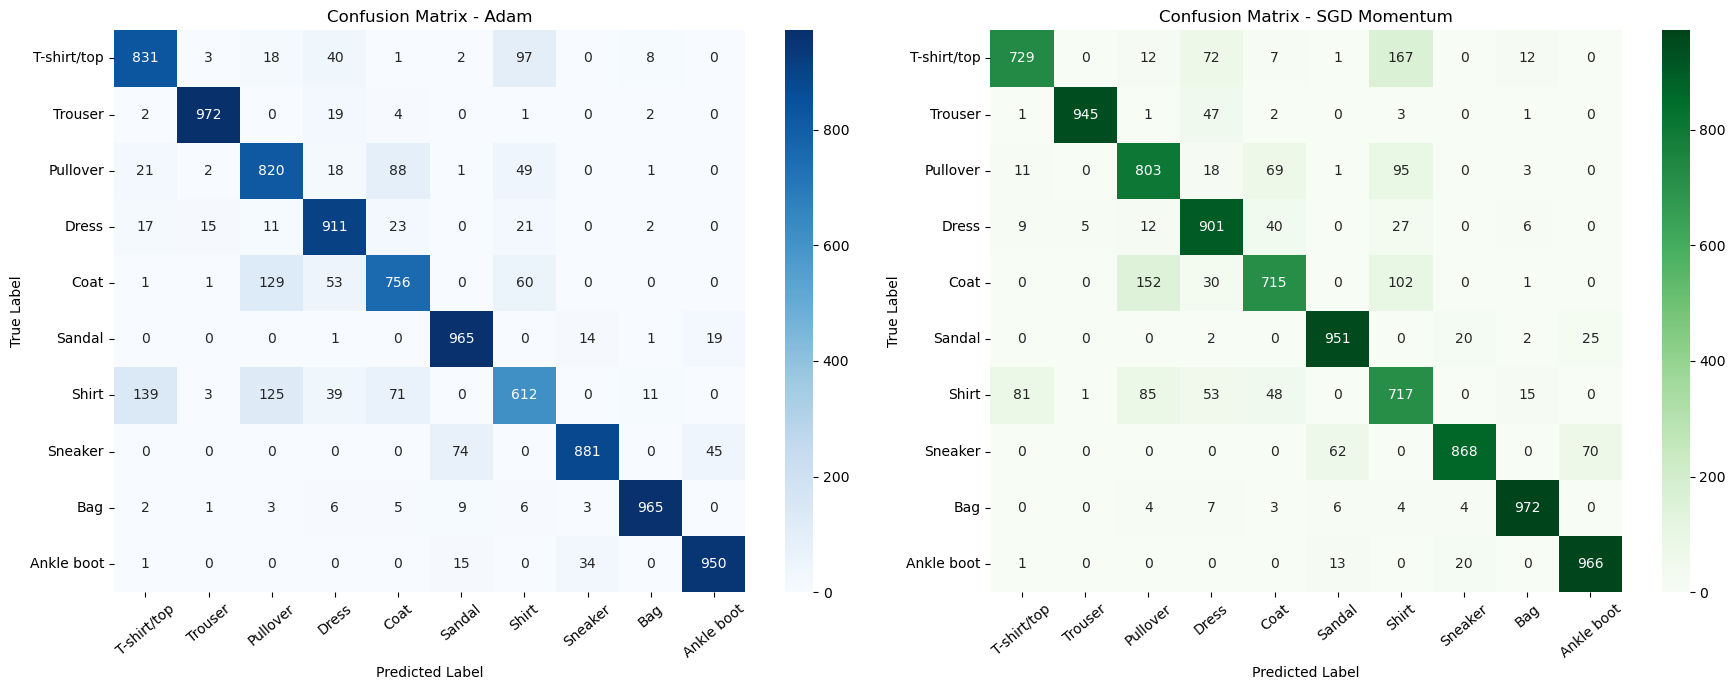

In [10]:
def get_predictions(model, data_loader):
    model.eval()
    predictions = []
    actuals = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            outputs = model(images)
            predictions.extend(outputs.argmax(dim=1).cpu().numpy())
            actuals.extend(labels.numpy())

    return np.array(actuals), np.array(predictions)


y_true, y_pred_adam = get_predictions(model_adam, test_loader)
_, y_pred_sgd = get_predictions(model_sgd, test_loader)

adam_test_accuracy = accuracy_score(y_true, y_pred_adam)
sgd_test_accuracy = accuracy_score(y_true, y_pred_sgd)

print("ADAM - TEST RESULTS")
print("Accuracy:", round(adam_test_accuracy, 4))
print(classification_report(
    y_true, y_pred_adam, target_names=class_names, digits=4, zero_division=0
))

print("SGD - TEST RESULTS")
print("Accuracy:", round(sgd_test_accuracy, 4))
print(classification_report(
    y_true, y_pred_sgd, target_names=class_names, digits=4, zero_division=0
))

comparison_df = pd.DataFrame([
    {"Model": "MLP", "Optimizer": "Adam", "Test Accuracy": adam_test_accuracy},
    {"Model": "MLP", "Optimizer": "SGD Momentum", "Test Accuracy": sgd_test_accuracy}
])
display(comparison_df)

cm_adam = confusion_matrix(y_true, y_pred_adam)
cm_sgd = confusion_matrix(y_true, y_pred_sgd)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(cm_adam, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Confusion Matrix - Adam")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(cm_sgd, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title("Confusion Matrix - SGD Momentum")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

for ax in axes:
    ax.tick_params(axis="x", rotation=40)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


## 10. Trực quan hóa Loss và Accuracy
So sánh đường cong huấn luyện và validation của hai Optimizer.

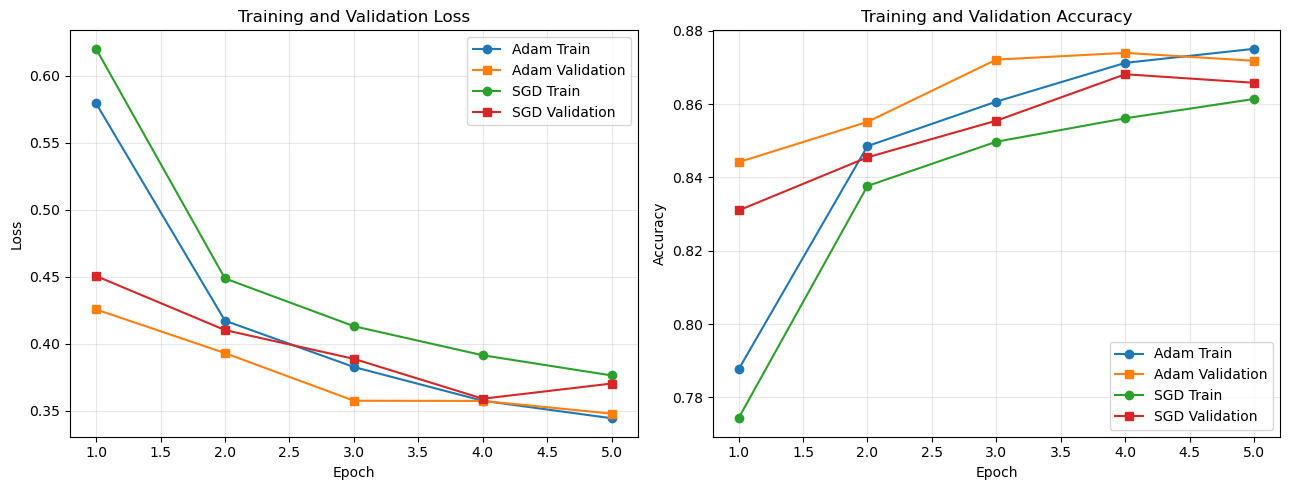

In [11]:
epoch_range = range(1, epochs + 1)

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
plt.plot(epoch_range, history_adam["train_loss"], marker="o", label="Adam Train")
plt.plot(epoch_range, history_adam["val_loss"], marker="s", label="Adam Validation")
plt.plot(epoch_range, history_sgd["train_loss"], marker="o", label="SGD Train")
plt.plot(epoch_range, history_sgd["val_loss"], marker="s", label="SGD Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epoch_range, history_adam["train_acc"], marker="o", label="Adam Train")
plt.plot(epoch_range, history_adam["val_acc"], marker="s", label="Adam Validation")
plt.plot(epoch_range, history_sgd["train_acc"], marker="o", label="SGD Train")
plt.plot(epoch_range, history_sgd["val_acc"], marker="s", label="SGD Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 11. Hiển thị ảnh thực tế và kết quả dự đoán
Mỗi ảnh được hiển thị cùng nhãn thực tế và nhãn mô hình dự đoán.

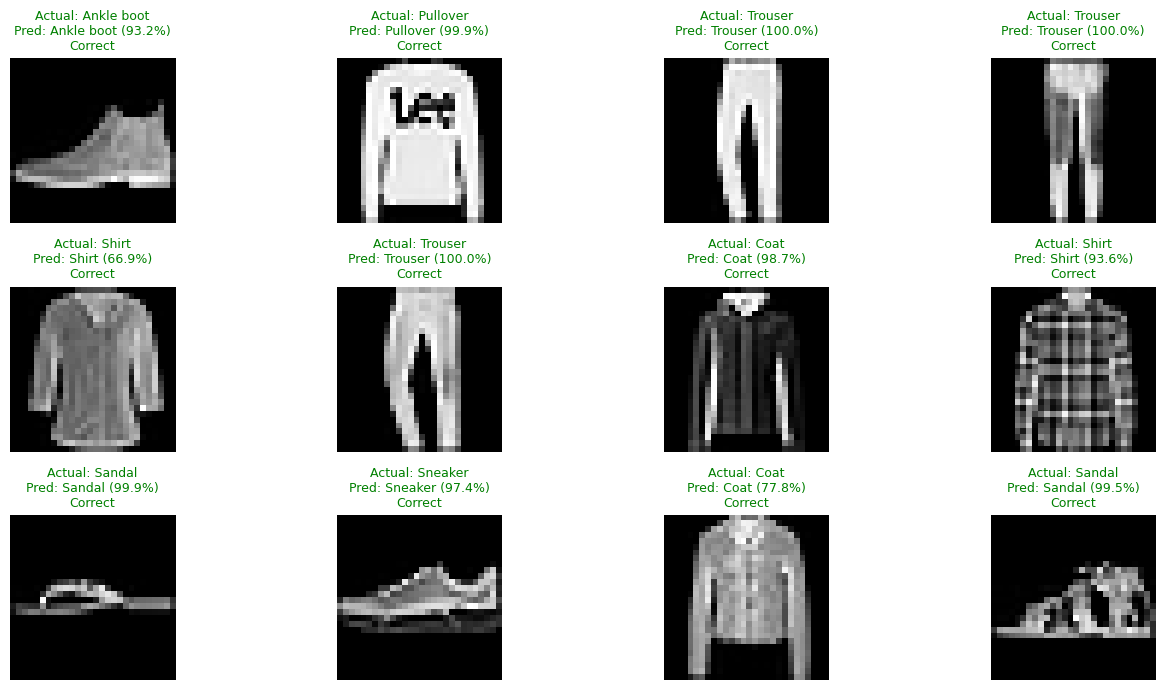

In [12]:
model_adam.eval()
images, labels = next(iter(test_loader))
images_device = images.to(device)

with torch.no_grad():
    outputs = model_adam(images_device)
    probabilities = torch.softmax(outputs, dim=1)
    confidences, predictions = probabilities.max(dim=1)

plt.figure(figsize=(14, 7))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    image = images[i].squeeze().numpy() * 0.5 + 0.5
    actual = class_names[labels[i].item()]
    predicted = class_names[predictions[i].item()]
    confidence = confidences[i].item() * 100
    correct = actual == predicted

    plt.imshow(image, cmap="gray")
    plt.title(
        f"Actual: {actual}\nPred: {predicted} ({confidence:.1f}%)\n"
        f"{'Correct' if correct else 'Incorrect'}",
        color="green" if correct else "red",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


## 12. Lưu và tải lại mô hình
Lưu `state_dict` của mô hình đã huấn luyện, sau đó khởi tạo lại kiến trúc và nạp trọng số để kiểm tra dự đoán.

In [13]:
model_path = "fashion_mnist_mlp.pth"
torch.save(model_adam.state_dict(), model_path)
print("Đã lưu mô hình tại:", os.path.abspath(model_path))

loaded_model = FashionMLP().to(device)
loaded_model.load_state_dict(torch.load(model_path, map_location=device))
loaded_model.eval()

loaded_y_true, loaded_y_pred = get_predictions(loaded_model, test_loader)
loaded_accuracy = accuracy_score(loaded_y_true, loaded_y_pred)

print("Test Accuracy trước khi lưu:", round(adam_test_accuracy, 4))
print("Test Accuracy sau khi tải lại:", round(loaded_accuracy, 4))
print("Kết quả tải lại có khớp:", np.isclose(adam_test_accuracy, loaded_accuracy))

sample_images, sample_labels = next(iter(test_loader))
with torch.no_grad():
    sample_outputs = loaded_model(sample_images[:5].to(device))
    sample_predictions = sample_outputs.argmax(dim=1).cpu().numpy()

print("Kết quả sau khi tải lại mô hình:")
for i in range(5):
    actual = class_names[sample_labels[i].item()]
    predicted = class_names[int(sample_predictions[i])]
    print(f"Ảnh {i + 1}: Thực tế = {actual} | Dự đoán = {predicted}")


Đã lưu mô hình tại: d:\deeplerning\Lap\Deep-Learning\practice_chap2\fashion_mnist_mlp.pth


Test Accuracy trước khi lưu: 0.8663
Test Accuracy sau khi tải lại: 0.8663
Kết quả tải lại có khớp: True
Kết quả sau khi tải lại mô hình:
Ảnh 1: Thực tế = Ankle boot | Dự đoán = Ankle boot
Ảnh 2: Thực tế = Pullover | Dự đoán = Pullover
Ảnh 3: Thực tế = Trouser | Dự đoán = Trouser
Ảnh 4: Thực tế = Trouser | Dự đoán = Trouser
Ảnh 5: Thực tế = Shirt | Dự đoán = Shirt


## 13. Nhận xét và kết luận

Sau khi chạy toàn bộ Notebook, sử dụng kết quả thực tế để hoàn thiện phần nhận xét:

- FashionMNIST là bài toán phân loại ảnh gồm 10 lớp quần áo và phụ kiện.
- Mỗi ảnh có kích thước 28×28 pixel, được chuyển thành Tensor có dạng (1, 28, 28) và chuẩn hóa trước khi đưa vào mô hình.
- Mô hình MLP làm phẳng ảnh thành vector 784 chiều, đi qua hai hidden layers và dự đoán một trong 10 lớp.
- Adam và SGD Momentum được so sánh trên cùng kiến trúc và cùng trọng số khởi tạo ban đầu.
- Các thử nghiệm Hyperparameters cho thấy thay đổi Learning Rate, Batch Size và số Neurons có thể làm thay đổi kết quả Validation.
- Accuracy, Precision, Recall, F1-score và Confusion Matrix được sử dụng để đánh giá mô hình trên tập Test.
- Mô hình được lưu bằng `state_dict`, tải lại và kiểm tra độ chính xác để xác nhận quá trình lưu/tải.

**Bảng kết quả cần ghi sau khi chạy:**

| Mô hình | Optimizer | Test Accuracy |
|---|---|---|
| MLP | Adam | Lấy từ kết quả chạy |
| MLP | SGD Momentum | Lấy từ kết quả chạy |

**Lưu ý:** Không điền số liệu dự đoán trước khi huấn luyện. Kết quả phụ thuộc vào số Epoch, Learning Rate, Batch Size, kiến trúc và thiết bị huấn luyện.
